# Advección periódica con cuatro armónicos: barrido PCA

**Pregunta experimental.** ¿Se mantiene el comportamiento observado al cambiar la condición inicial de dos frecuencias por una condición periódica con más estructura espectral?

La condición inicial es una serie de Fourier de cuatro armónicos:

\[u_0(x)=\sin(\pi x)+0.5\cos(2\pi x)+0.25\sin(3\pi x)+0.125\cos(4\pi x),\qquad u(x,t)=u_0(x-ct).\]

Se vuelve a comparar la PINN base con PCA al 99% de varianza y con varios valores fijos de `k`.

## Protocolo empírico

- Diez semillas (2041–2050), mismas particiones, minibatches, puntos PDE, tiempos de frontera y puntos iniciales para todos los métodos dentro de cada semilla.
- 2000 pasos, evaluación cada 100 pasos y arquitectura con número de parámetros emparejado.
- PCA se ajusta solo con snapshots de los tiempos de entrenamiento. La pérdida física se calcula mediante autodiferenciación en todos los modelos.
- El error de prueba, residuo PDE y defecto de periodicidad se evalúan sobre los mismos tiempos de prueba y grilla. El residuo se estima con diferencias sobre la grilla para que la evaluación sea común.
- Se reporta tiempo de pipeline, incluyendo el ajuste de PCA; el tiempo de compilación se registra aparte.

La condición inicial de cuatro armónicos se diseñó como una prueba más rica, pero sigue siendo un único problema analítico. Los resultados no prueban generalización a otros tipos de PDE.

In [ ]:
from pathlib import Path
import json
from IPython.display import display, HTML, SVG

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RUN_DIR = ROOT / "results/advection/base_vs_pca/fourier_rich_k_sweep_10_seeds_v1"
RESULT = json.loads((RUN_DIR / "summary.json").read_text(encoding="utf-8"))


def html_table(headers, rows):
    head = "".join(f"<th>{h}</th>" for h in headers)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    return f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"


def stat(name, metric, digits=4):
    value = RESULT["summary"][name][metric]
    return f"{value['mean']:.{digits}g} ± {value['std']:.{digits}g}"


## Métricas en prueba

Valores reportados como media ± desviación estándar en las diez semillas.

In [1]:
ORDER = ["PINN base", "PCA AD 99%", "PCA AD k=2", "PCA AD k=6", "PCA AD k=8"]
rows = []
for name in ORDER:
    item = RESULT["summary"][name]
    k = "—" if item["k"] is None else f"{item['k']['mean']:.0f}"
    retained = "—" if item["retained_variance"] is None else f"{100*item['retained_variance']['mean']:.4f}% ± {100*item['retained_variance']['std']:.3g}%"
    rows.append([name, k, retained, stat(name, "test_relative_l2"), stat(name, "test_pde_residual_rms"), stat(name, "test_periodic_boundary_rms", 3), stat(name, "pipeline_seconds", 3)])
display(HTML(html_table(["Modelo", "k", "Varianza retenida", "Error relativo L2 (prueba)", "Residuo PDE RMS (prueba)", "Defecto periódico RMS", "Pipeline (s)"], rows)))


Modelo,k,Varianza retenida,Error relativo L2 (prueba),Residuo PDE RMS (prueba),Defecto periódico RMS,Pipeline (s)
PINN base,—,—,0.06016 ± 0.008801,0.02283 ± 0.003118,0.0639 ± 0.0126,3.12 ± 0.105
PCA AD 99%,4,99.4038% ± 0.038%,0.1743 ± 0.02442,0.5796 ± 0.07295,1.17e-07 ± 4.21e-08,2.62 ± 0.0521
PCA AD k=2,2,90.1950% ± 0.494%,0.4782 ± 0.02262,1.025 ± 0.1005,6.67e-08 ± 5.21e-08,2.62 ± 0.0667
PCA AD k=6,6,99.9958% ± 0.000564%,0.06858 ± 0.005838,0.197 ± 0.04511,1.35e-07 ± 3.58e-08,2.72 ± 0.16
PCA AD k=8,8,100.0000% ± 9.4e-06%,0.1089 ± 0.01156,0.07312 ± 0.01495,1.97e-07 ± 1.15e-07,2.72 ± 0.149


## Error de solución frente a residuo PDE

Los dos criterios pueden ordenar los modelos de forma distinta: el error mide fidelidad a la solución analítica y el residuo mide cuánto satisface la ecuación diferencial en la evaluación.

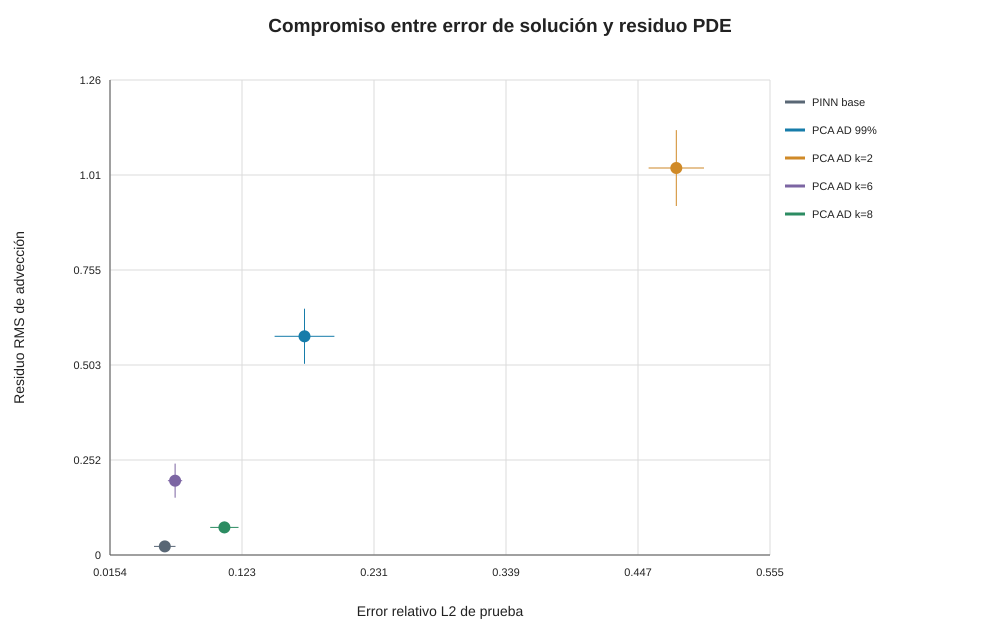

In [1]:
display(SVG(filename=str(RUN_DIR / "error_residual_tradeoff.svg")))

## Comparaciones y evolución durante el entrenamiento

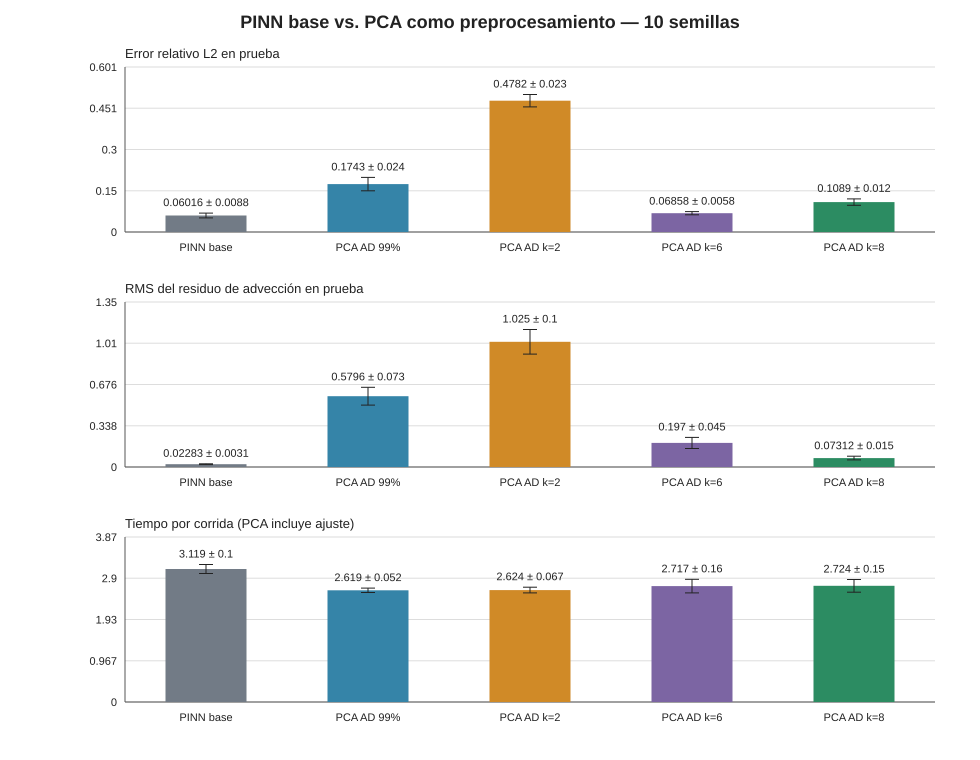

In [1]:
display(SVG(filename=str(RUN_DIR / "comparison.svg")))

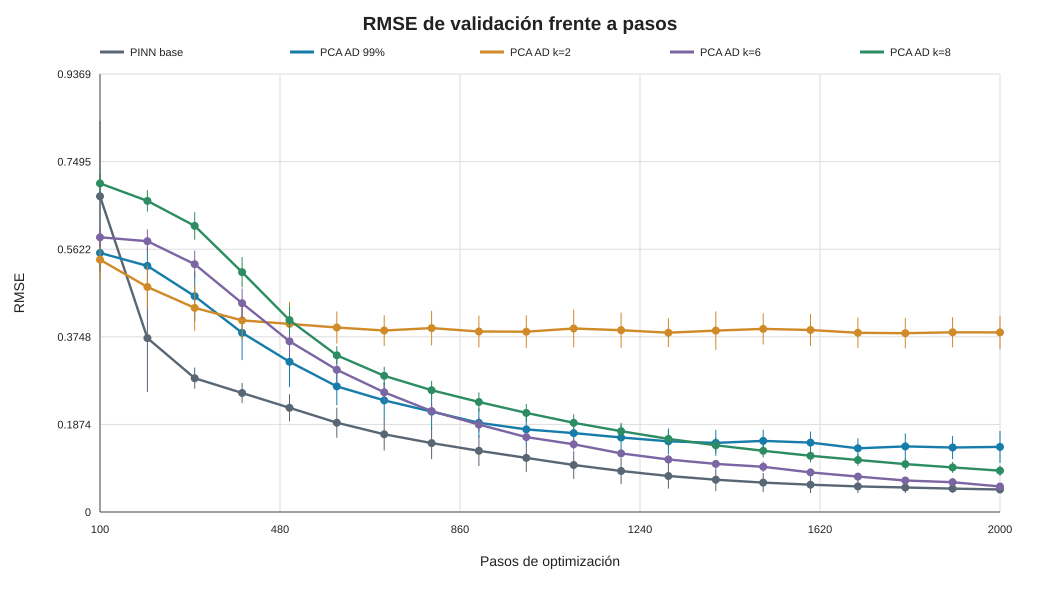

In [1]:
display(SVG(filename=str(RUN_DIR / "validation_rmse_vs_steps.svg")))

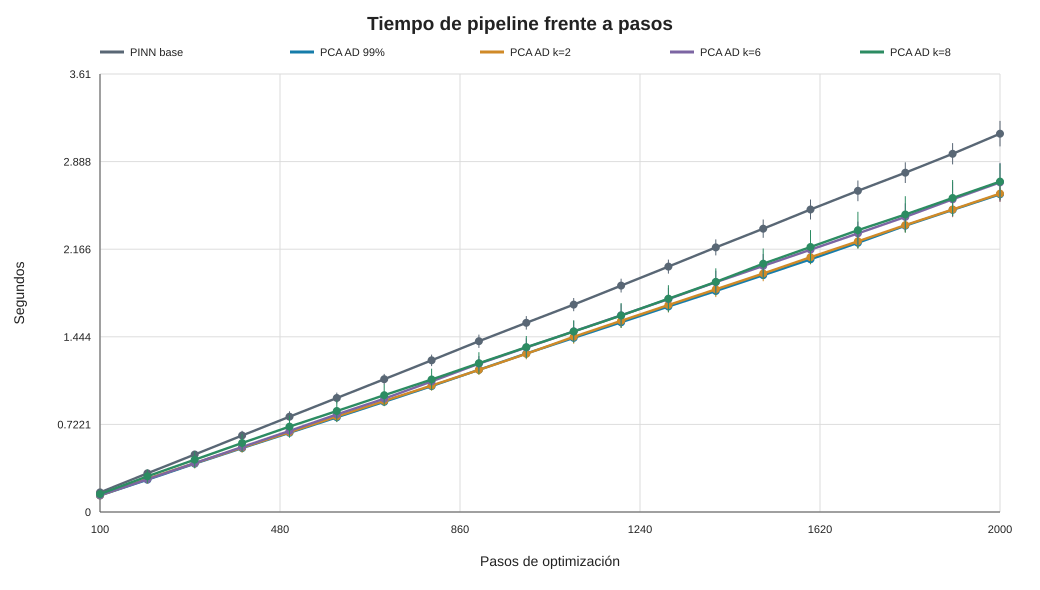

In [1]:
display(SVG(filename=str(RUN_DIR / "pipeline_time_vs_steps.svg")))

## Diferencias pareadas contra PINN base

`Δ` corresponde a PCA menos PINN base por semilla. Un valor negativo favorece a PCA. El conteo muestra en cuántas semillas PCA obtuvo menor valor para esa métrica.

In [1]:
rows = []
for name in ORDER[1:]:
    m = RESULT["paired_differences_PCA_minus_base"][name]
    er, pde, tm = (m[key] for key in ("test_relative_l2", "test_pde_residual_rms", "pipeline_seconds"))
    rows.append([name, f"{er['PCA_minus_base_mean']:+.5f}", f"{er['PCA_better_count']}/10", f"{pde['PCA_minus_base_mean']:+.5f}", f"{pde['PCA_better_count']}/10", f"{tm['PCA_minus_base_mean']:+.3f}"])
display(HTML(html_table(["Modelo", "Δ error L2 medio", "Semillas con error menor", "Δ residuo PDE medio", "Semillas con residuo menor", "Δ pipeline (s)"], rows)))


Modelo,Δ error L2 medio,Semillas con error menor,Δ residuo PDE medio,Semillas con residuo menor,Δ pipeline (s)
PCA AD 99%,+0.11419,0/10,+0.55681,0/10,-0.500
PCA AD k=2,+0.41800,0/10,+1.00258,0/10,-0.494
PCA AD k=6,+0.00841,2/10,+0.17416,0/10,-0.401
PCA AD k=8,+0.04872,0/10,+0.05029,0/10,-0.395


## Interpretación

- La selección por 99% eligió **k=4** (varianza retenida media **99,40%**). Sin embargo, su error relativo L2 (**0,174**) y residuo PDE (**0,580**) fueron mayores que los de la PINN base (**0,060** y **0,0228**, respectivamente).
- Entre los PCA probados, **k=6** dio el menor error de solución (**0,0686**) y fue mejor que la base en 2/10 semillas; su error medio siguió siendo ligeramente mayor que el de la base. Esto contrasta con el benchmark anterior, donde `k=4` tuvo el mejor error de solución.
- **k=8** tuvo el menor residuo PDE entre las variantes PCA (**0,0731**), pero no el menor error de solución (**0,109**). Ninguno de los valores PCA evaluados superó a la PINN base en promedio para ambas métricas.
- Todas las variantes PCA fueron más rápidas en tiempo de pipeline (aprox. 2,62–2,72 s frente a 3,12 s de la base) y tuvieron un defecto periódico prácticamente nulo. La ganancia de tiempo vino acompañada de un deterioro de ajuste en esta condición.
- El conteo al 99% no fue suficiente para seleccionar una representación con buen desempeño en todas las métricas. El resultado también confirma que aumentar `k` no produce una mejora monótona: k6 mejora el error frente a k4, mientras k8 reduce el residuo pero vuelve a aumentar el error.

**Conclusión acotada:** en esta condición inicial más rica, PCA redujo el tiempo y respetó mejor la periodicidad, pero con 2000 pasos no igualó la PINN base en error de solución ni residuo PDE. Es una evidencia del costo de compresión bajo este protocolo, no una conclusión general sobre PCA.

## Reproducibilidad

- Configuración: `configs/advection_fourier_k_sweep.json`
- Ejecutor: `scripts/run_advection_k_sweep.py`
- Resultados: `results/advection/base_vs_pca/fourier_rich_k_sweep_10_seeds_v1/`

Desde la raíz del repositorio:

```powershell
.venv-jax-latest\Scripts\python.exe scripts\run_advection_k_sweep.py --config configs\advection_fourier_k_sweep.json
```
